NETFLIX DATA ANALYSIS PROJECT

Dataset loaded successfully!

First 5 records:
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  Septe

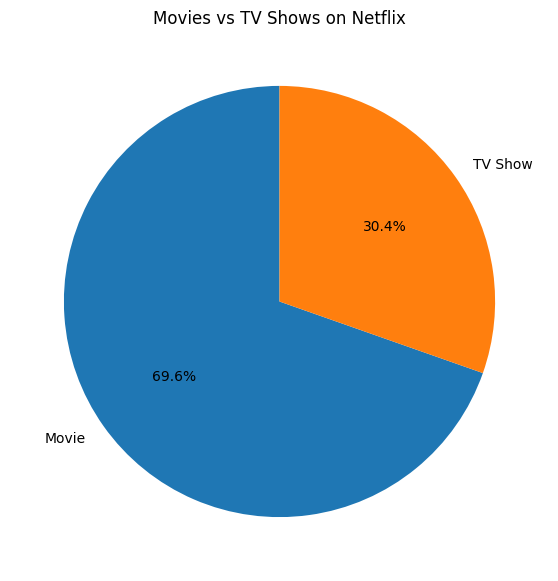

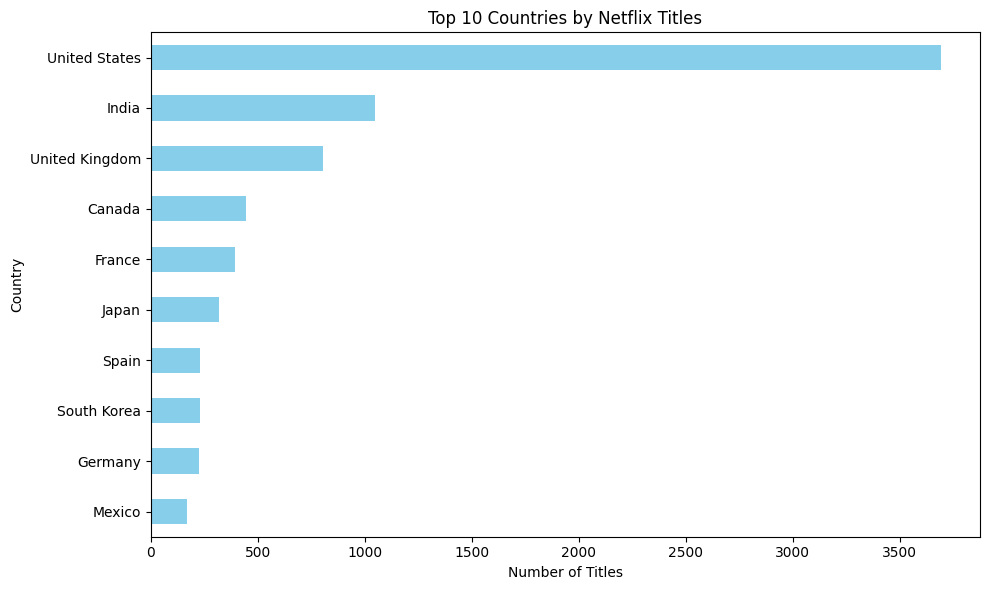

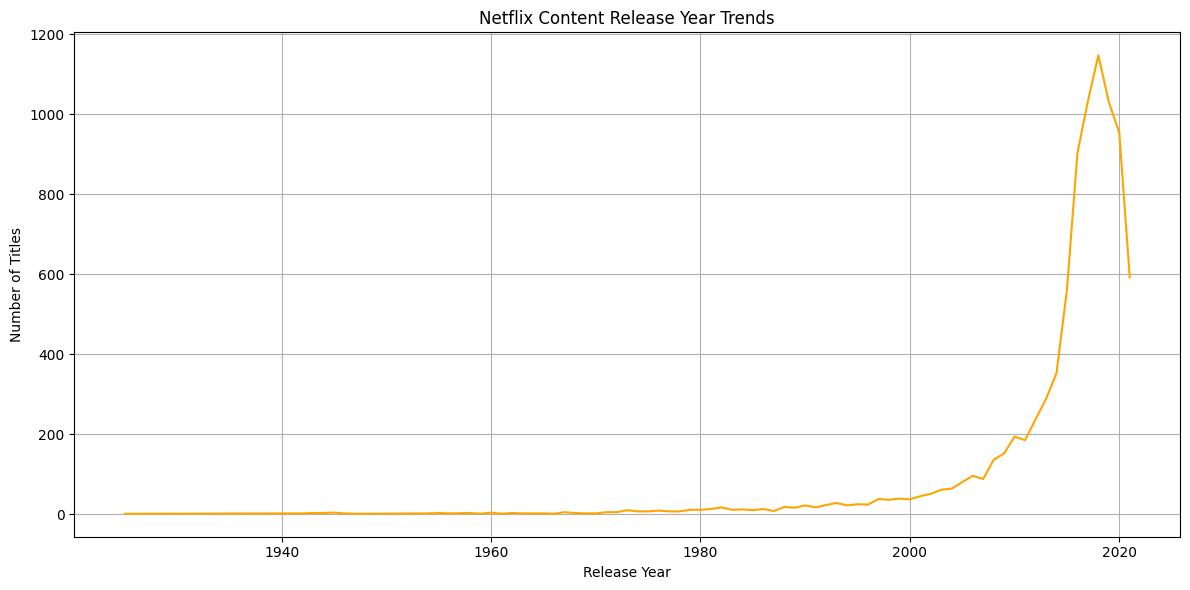

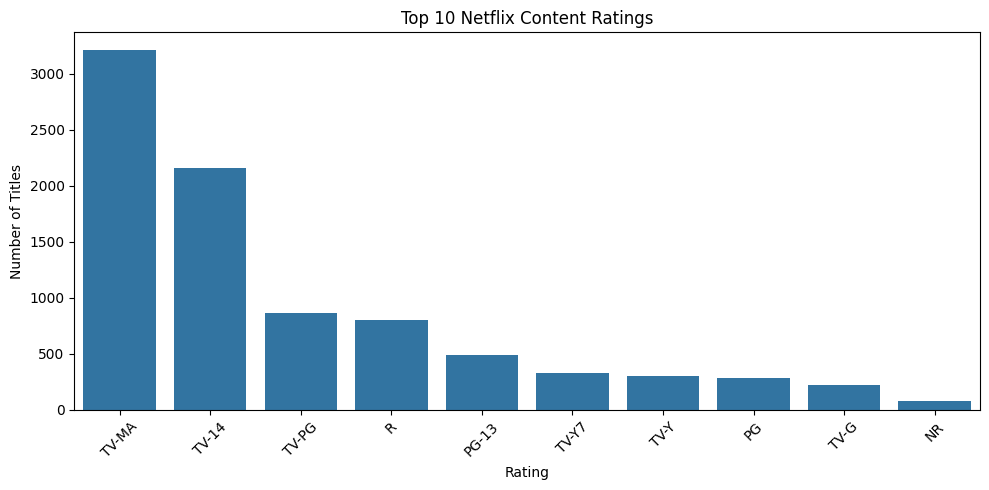


CONTENT TYPE BY RELEASE YEAR:
type          Movie  TV Show
release_year                
2012            173       64
2013            225       63
2014            264       88
2015            398      162
2016            658      244
2017            767      265
2018            767      380
2019            633      397
2020            517      436
2021            277      315

FINAL PROJECT INSIGHTS
1. Total titles analysed: 8807
2. Total movies: 6131
3. Total TV shows: 2676
4. Movies account for 69.62% of content.
5. TV Shows account for 30.38% of content.
6. Top content-producing country: United States
7. Most common release year: 2018
8. Most common content rating: TV-MA

9. Top 5 countries:
country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Name: count, dtype: int64

10. Missing values were checked and handled.

PROJECT COMPLETED SUCCESSFULLY!


In [1]:

# MODULE 05 - DATA SCIENCE MINI PROJECT
# PROJECT: NETFLIX DATA ANALYSIS

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("NETFLIX DATA ANALYSIS PROJECT")
print("=" * 55)

# 2. Load real-world dataset
url = "https://raw.githubusercontent.com/pratyaksh-tech01/Codomax_Internship/main/netflix_titles.csv"

df = pd.read_csv(url)

print("\nDataset loaded successfully!")

# 3. Explore the dataset
print("\nFirst 5 records:")
print(df.head())

print("\nDataset dimensions:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe(include="all"))

# 4. Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# 5. Clean the dataset
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna("Not Rated")
df["date_added"] = df["date_added"].fillna("Unknown")

df["date_added"] = pd.to_datetime(
    df["date_added"].str.strip(),
    format="%B %d, %Y",
    errors="coerce"
)

df["release_year"] = pd.to_numeric(
    df["release_year"], errors="coerce"
)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

# 6. Analyse Movies vs TV Shows
type_counts = df["type"].value_counts()

print("\nMovies vs TV Shows:")
print(type_counts)

print("\nContent percentage:")
print((type_counts / len(df) * 100).round(2))

# 7. Top 10 countries
countries = (
    df[df["country"] != "Unknown"]["country"]
    .str.split(",")
    .explode()
    .str.strip()
)

top_countries = countries.value_counts().head(10)

print("\nTop 10 content-producing countries:")
print(top_countries)

# 8. Analyse release years
year_counts = df["release_year"].value_counts().sort_index()

print("\nTop 10 release years:")
print(df["release_year"].value_counts().head(10))

# 9. Visualisation - Movies vs TV Shows
plt.figure(figsize=(7, 7))
plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Movies vs TV Shows on Netflix")
plt.show()

# 10. Visualisation - Top 10 countries
plt.figure(figsize=(10, 6))
top_countries.sort_values().plot(
    kind="barh",
    color="skyblue"
)
plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

# 11. Visualisation - Release year trends
plt.figure(figsize=(12, 6))
year_counts.plot(kind="line", color="orange")
plt.title("Netflix Content Release Year Trends")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.tight_layout()
plt.show()

# 12. Visualisation - Content ratings
rating_counts = df["rating"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)
plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 13. Additional analysis
print("\nCONTENT TYPE BY RELEASE YEAR:")
print(
    df.groupby(["release_year", "type"])
    .size()
    .unstack(fill_value=0)
    .tail(10)
)

# 14. Generate meaningful insights
movie_count = type_counts.get("Movie", 0)
tv_count = type_counts.get("TV Show", 0)

movie_percentage = movie_count / len(df) * 100
tv_percentage = tv_count / len(df) * 100

print("\n" + "=" * 55)
print("FINAL PROJECT INSIGHTS")
print("=" * 55)

print(f"1. Total titles analysed: {len(df)}")
print(f"2. Total movies: {movie_count}")
print(f"3. Total TV shows: {tv_count}")

print(f"4. Movies account for {movie_percentage:.2f}% of content.")
print(f"5. TV Shows account for {tv_percentage:.2f}% of content.")

print(f"6. Top content-producing country: {top_countries.index[0]}")

print(f"7. Most common release year: "
      f"{int(df['release_year'].mode()[0])}")

print(f"8. Most common content rating: "
      f"{df['rating'].mode()[0]}")

print("\n9. Top 5 countries:")
print(top_countries.head())

print("\n10. Missing values were checked and handled.")

print("\nPROJECT COMPLETED SUCCESSFULLY!")
